# Heart Disease Prediction with Bayesian Networks

## 1. Project Overview

This notebook predicts the presence of heart disease from the four UCI Heart Disease databases
(Cleveland, Hungarian, Switzerland, VA Long Beach; 920 patients in total). Four standard
classifiers are compared against two Bayesian Networks: one whose structure is written by hand
from clinical reasoning, and one whose structure is learned from data with Hill Climbing on the
BIC score.

The reason for using Bayesian Networks here is that a real patient rarely has every test result
available at once. A trained classifier needs all 13 features to produce an output. A Bayesian
Network can answer `P(target | evidence)` for *any* subset of observed features, which lets us
also ask which test is worth ordering next.

| Stage | Method |
|---|---|
| Preprocessing | Split before imputation; training-set modes only; medically motivated discretisation |
| Unsupervised | PCA (2 components) + K-Means (k=2) on the standardised continuous features |
| Supervised | Logistic Regression, Random Forest, Categorical Naive Bayes, MLP |
| BN structure | Hand-built domain network; Hill Climbing + BIC |
| Exact inference | Variable Elimination |
| Approximate inference | Likelihood Weighting |
| Test selection | Expected information gain and Value of Perfect Information |
| Decision rule | Cost-sensitive threshold from an explicit reward matrix |

Metrics reported on the held-out test set: accuracy, precision, recall, F1, ROC-AUC.

---
## 2. Imports and Configuration

In [1]:
import logging
import warnings

warnings.filterwarnings('ignore')
logging.getLogger('pgmpy').setLevel(logging.ERROR)

import textwrap
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from pgmpy.estimators import BIC, BayesianEstimator, HillClimbSearch
from pgmpy.factors.discrete import State
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.sampling import BayesianModelSampling

RANDOM_STATE = 42


def find_repo_root():
    for directory in [Path.cwd(), *Path.cwd().parents]:
        if (directory / 'notebooks' / 'heart_disease_prediction.ipynb').exists():
            return directory
    raise RuntimeError(
        'Could not locate the repository root from '
        f'{Path.cwd()}. Run this notebook from inside a clone of the repository.'
    )


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / 'data'
RESULTS_DIR = REPO_ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.titlesize': 12})

---
## 3. Dataset Loading

### Source

All four databases come from the UCI *Heart Disease* repository
(<https://archive.ics.uci.edu/dataset/45/heart+disease>). We use the `processed.*` files, which
contain the 14-column subset that essentially all published work on this dataset uses.

| File | Institution | Patients |
|---|---|---|
| `processed.cleveland.data` | Cleveland Clinic Foundation | 303 |
| `processed.hungarian.data` | Hungarian Institute of Cardiology, Budapest | 294 |
| `processed.switzerland.data` | University Hospital, Zürich | 123 |
| `processed.va.data` | VA Medical Center, Long Beach | 200 |
| **Total** | | **920** |

The files have no header row and use `?` for missing values. If they are not present in the
repository's `data/` directory the loader downloads them from UCI and caches them there, so the
notebook runs on a fresh clone.

Paths are resolved against the repository root, which the configuration cell locates by walking up
from the current working directory. The notebook therefore works whether the kernel starts in
`notebooks/` (what Jupyter does by default) or at the repository root (what some editors do), and
it never writes outside the repository.

### Columns

The `processed` files use the original UCI codes, which are **not** zero-based for every variable.
Getting this wrong is a common source of bugs, so the exact domains are declared explicitly below
and asserted after preprocessing.

| Column | Description | Values in these files |
|---|---|---|
| `age` | Age in years | continuous |
| `sex` | Sex | 0 = female, 1 = male |
| `cp` | Chest pain type | 1 = typical angina, 2 = atypical, 3 = non-anginal, 4 = asymptomatic |
| `trestbps` | Resting blood pressure (mm Hg) | continuous |
| `chol` | Serum cholesterol (mg/dL) | continuous |
| `fbs` | Fasting blood sugar > 120 mg/dL | 0 / 1 |
| `restecg` | Resting ECG | 0 = normal, 1 = ST-T abnormality, 2 = LV hypertrophy |
| `thalach` | Maximum heart rate achieved | continuous |
| `exang` | Exercise-induced angina | 0 / 1 |
| `oldpeak` | ST depression, exercise vs rest | continuous |
| `slope` | Slope of peak exercise ST segment | 1 = up, 2 = flat, 3 = down |
| `ca` | Major vessels coloured by fluoroscopy | 0–3 |
| `thal` | Thalassemia / perfusion scan | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` → `target` | Diagnosis | 0–4, binarised to 0 vs > 0 |

In [2]:
COLUMN_NAMES = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target',
]
SOURCE_FILES = {
    'Cleveland': 'processed.cleveland.data',
    'Hungarian': 'processed.hungarian.data',
    'Switzerland': 'processed.switzerland.data',
    'VA Long Beach': 'processed.va.data',
}
UCI_BASE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/'


def load_source(filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(exist_ok=True)
        print(f'  downloading {filename} from UCI ...')
        urllib.request.urlretrieve(UCI_BASE + filename, path)
    df = pd.read_csv(path, names=COLUMN_NAMES, na_values='?')
    return df.apply(pd.to_numeric, errors='coerce')


frames = []
for institution, filename in SOURCE_FILES.items():
    df = load_source(filename)
    df['source'] = institution
    frames.append(df)
    print(f'  {institution:<14} {len(df):>4} rows')

raw_df = pd.concat(frames, ignore_index=True)
print()
print(f'Combined: {len(raw_df)} patients, {len(COLUMN_NAMES)} columns')
raw_df.head()

  Cleveland       303 rows
  Hungarian       294 rows
  Switzerland     123 rows
  VA Long Beach   200 rows

Combined: 920 patients, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,Cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,Cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,Cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,Cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,Cleveland


In [3]:
missing = raw_df.drop(columns='source').isna().sum()
missing_pct = (missing / len(raw_df) * 100).round(1)
pd.DataFrame({'missing': missing, 'percent': missing_pct}).query('missing > 0')

,missing,percent
trestbps,59,6.4
chol,30,3.3
fbs,90,9.8
restecg,2,0.2
thalach,55,6.0
exang,55,6.0
oldpeak,62,6.7
slope,309,33.6
ca,611,66.4
thal,486,52.8


`ca`, `thal` and `slope` are missing for a large share of patients. These come from tests that
the Hungarian, Switzerland and VA sites largely did not record. This is the most serious
limitation of the combined dataset and is revisited in the conclusion.

---
## 4. Data Preprocessing

### Zero-coded missing values

In `chol` and `trestbps` a value of `0` is not a measurement. It is how the Switzerland and VA
sites recorded "not measured" (all 123 Switzerland patients have `chol = 0`). Those zeros are
converted to `NaN` before imputation.

`oldpeak = 0` is **not** treated this way. Zero ST depression is a perfectly normal, very common
reading: 370 of the 858 recorded values are exactly 0, and those patients have a 34% disease rate
against 70% for the rest. Converting them to `NaN` would delete the most informative level of one
of the strongest predictors in the dataset.

### Order of operations

Imputation statistics are computed *after* the split and *only* from the training set, so no test
information reaches the training data.

1. Recode zero-as-missing, binarise the target
2. Stratified 80/20 train-test split
3. Compute per-column modes on the training set
4. Fill missing values in both splits with those training modes
5. Discretise into ordered bins

### Discretisation

Bayesian Networks over discrete variables need categorical inputs. The five continuous columns are
binned at clinically conventional cut-points rather than at quantiles.

| Column | Bin 0 | Bin 1 | Bin 2 |
|---|---|---|---|
| `age` | < 40 | 40–55 | > 55 |
| `trestbps` | < 120 (normal) | 120–140 (elevated) | > 140 (hypertensive) |
| `chol` | < 200 (desirable) | 200–240 (borderline) | > 240 (high) |
| `thalach` | < 100 | 100–150 | > 150 |
| `oldpeak` | ≤ 0 (none) | 0–2 (mild) | > 2 (significant) |

In [4]:
ZERO_IS_MISSING = ['chol', 'trestbps', 'thalach']

BIN_EDGES = {
    'age':      [-np.inf, 40, 55, np.inf],
    'trestbps': [-np.inf, 120, 140, np.inf],
    'chol':     [-np.inf, 200, 240, np.inf],
    'thalach':  [-np.inf, 100, 150, np.inf],
    'oldpeak':  [-np.inf, 0, 2, np.inf],
}
CATEGORICAL_STATES = {
    'sex': [0, 1], 'cp': [1, 2, 3, 4], 'fbs': [0, 1], 'restecg': [0, 1, 2],
    'exang': [0, 1], 'slope': [1, 2, 3], 'ca': [0, 1, 2, 3], 'thal': [3, 6, 7],
}
STATE_NAMES = {**{c: [0, 1, 2] for c in BIN_EDGES}, **CATEGORICAL_STATES, 'target': [0, 1]}

clean_df = raw_df.drop(columns='source').copy()
for col in ZERO_IS_MISSING:
    n_zero = int((clean_df[col] == 0).sum())
    clean_df[col] = clean_df[col].replace(0, np.nan)
    print(f'  {col:<9} {n_zero:>4} zero-coded values recoded as missing')

clean_df['target'] = (clean_df['target'] > 0).astype(int)
print()
print(f'Disease prevalence: {clean_df["target"].mean():.1%}')

  chol       172 zero-coded values recoded as missing
  trestbps     1 zero-coded values recoded as missing
  thalach      0 zero-coded values recoded as missing

Disease prevalence: 55.3%


In [5]:
train_raw, test_raw = train_test_split(
    clean_df, test_size=0.2, random_state=RANDOM_STATE, stratify=clean_df['target']
)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)

train_modes = train_raw.drop(columns='target').mode().iloc[0]
train_filled = train_raw.fillna(train_modes)
test_filled = test_raw.fillna(train_modes)


def discretize(df):
    out = df.copy()
    for col, edges in BIN_EDGES.items():
        out[col] = pd.cut(out[col], bins=edges, labels=[0, 1, 2]).astype(int)
    for col in CATEGORICAL_STATES:
        out[col] = out[col].astype(int)
    return out


train = discretize(train_filled)
test = discretize(test_filled)

assert not train.isna().any().any() and not test.isna().any().any()
for col, states in STATE_NAMES.items():
    for split_name, split in [('train', train), ('test', test)]:
        unexpected = set(split[col].unique()) - set(states)
        assert not unexpected, f'{split_name}.{col} contains {unexpected}, outside the codebook'

FEATURES = [c for c in train.columns if c != 'target']
y_train, y_test = train['target'].values, test['target'].values
X_train, X_test = train[FEATURES].values, test[FEATURES].values

print(f'Train {train.shape}   disease rate {train["target"].mean():.1%}')
print(f'Test  {test.shape}   disease rate {test["target"].mean():.1%}')
print()
print('Training modes used for imputation:')
print(train_modes.to_string())

Train (736, 14)   disease rate 55.3%
Test  (184, 14)   disease rate 55.4%

Training modes used for imputation:
age          54.0
sex           1.0
cp            4.0
trestbps    120.0
chol        220.0
fbs           0.0
restecg       0.0
thalach     140.0
exang         0.0
oldpeak       0.0
slope         2.0
ca            0.0
thal          3.0


In [6]:
train.groupby('oldpeak')['target'].agg(n='size', disease_rate='mean').round(3)

,n,disease_rate
oldpeak,,
0,351,0.399
1,303,0.634
2,82,0.915


The three `oldpeak` bins separate cleanly (40% → 63% → 92% disease rate), which confirms that
keeping the zeros as their own level was the right call.

---
## 5. Exploratory Data Analysis

Everything below is computed on the **training split only**, to stay consistent with the
leakage-free pipeline.

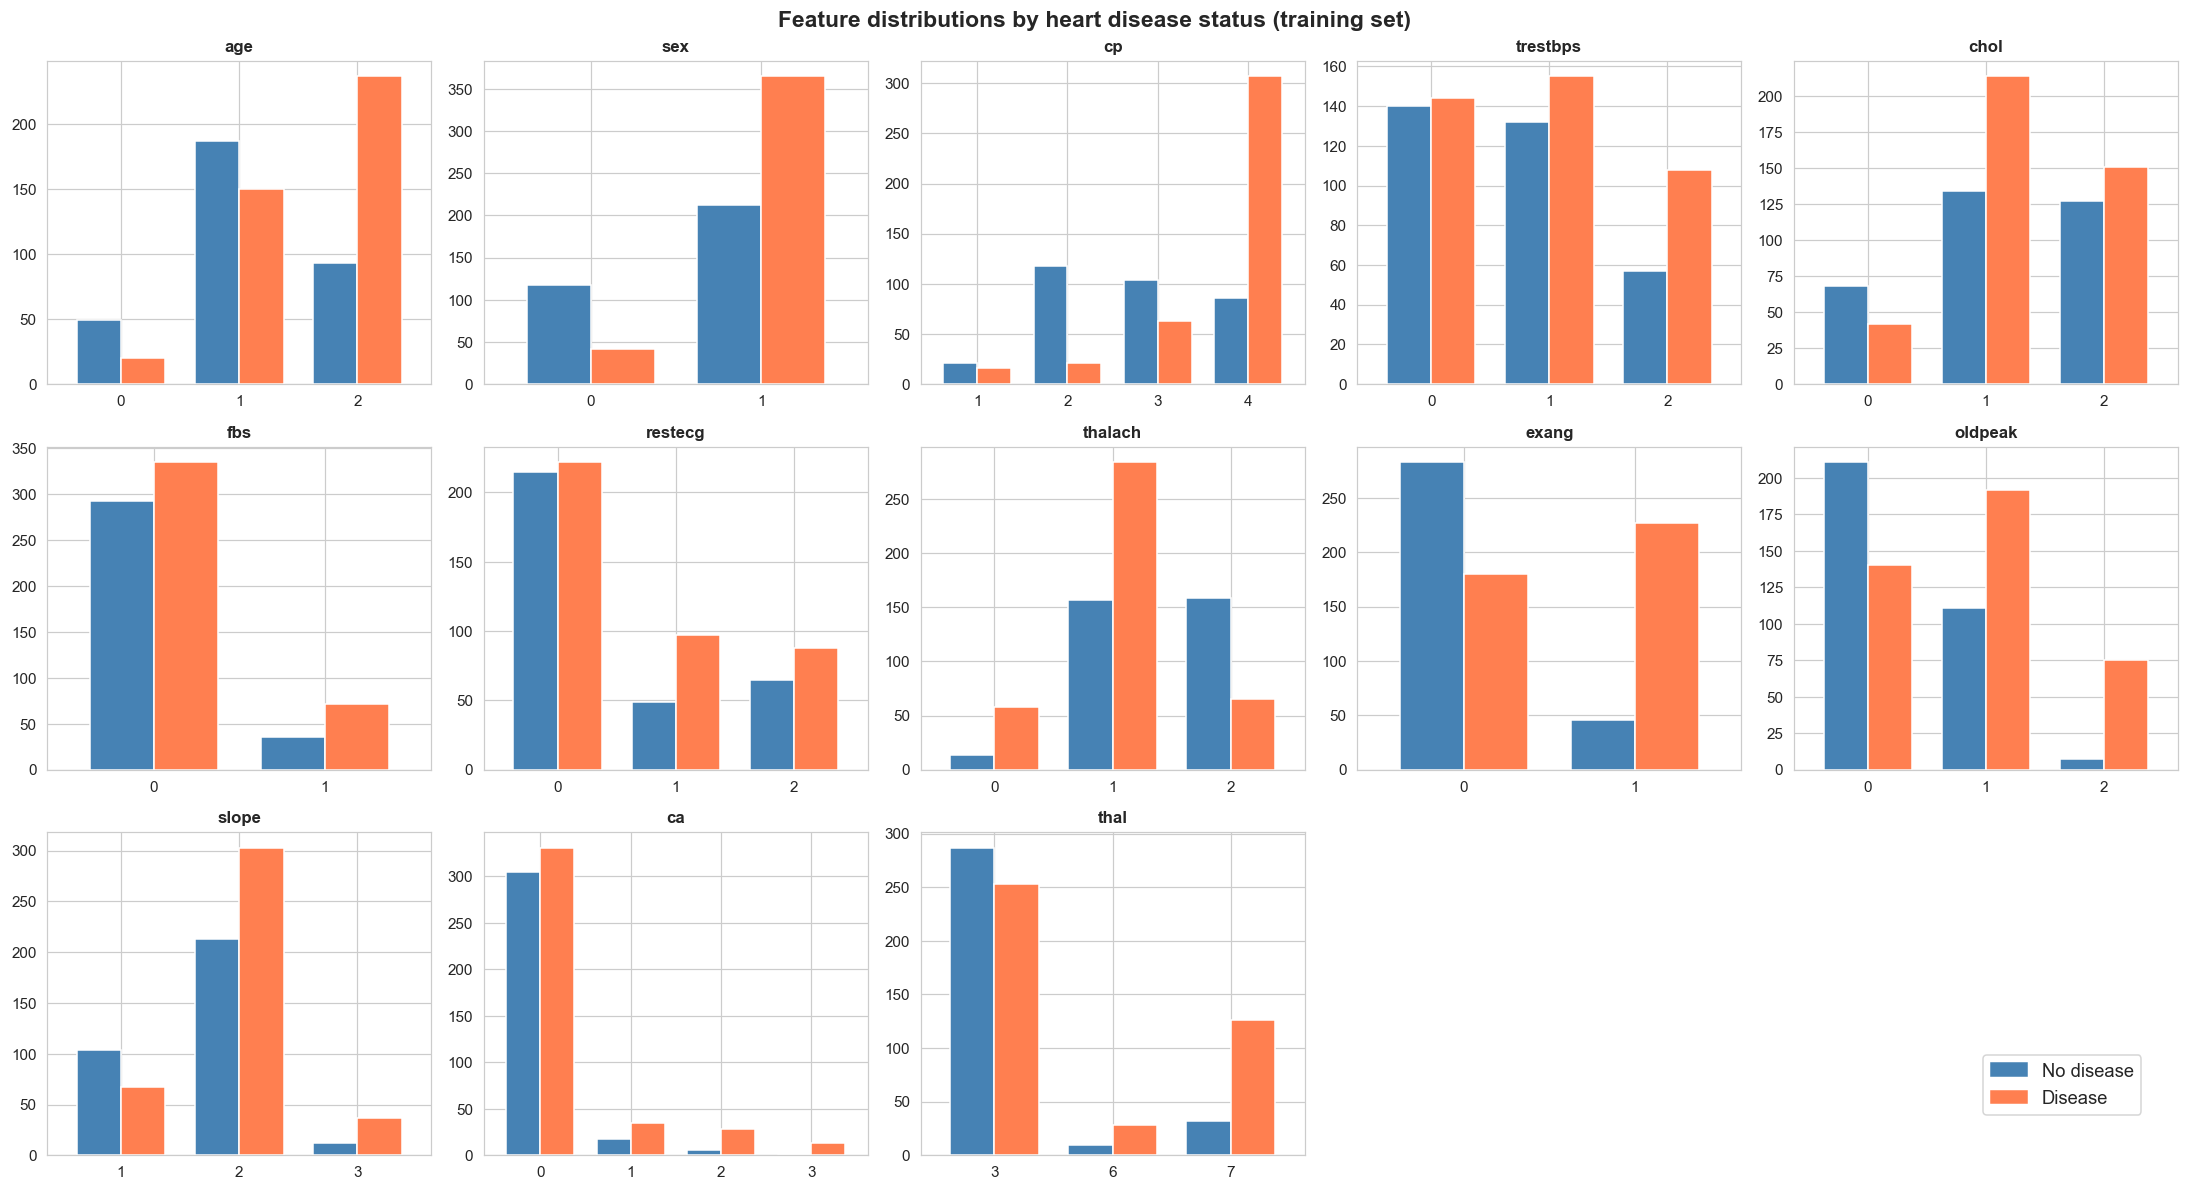

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
axes = axes.flatten()

for ax, col in zip(axes, FEATURES):
    counts = train.groupby([col, 'target']).size().unstack(fill_value=0)
    counts.plot(kind='bar', ax=ax, color=['steelblue', 'coral'], legend=False, width=0.75)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)

for ax in axes[len(FEATURES):]:
    ax.set_visible(False)

fig.legend(
    handles=[mpatches.Patch(color='steelblue', label='No disease'),
             mpatches.Patch(color='coral', label='Disease')],
    loc='lower right', fontsize=12, bbox_to_anchor=(0.98, 0.06),
)
fig.suptitle('Feature distributions by heart disease status (training set)',
             fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'eda_distributions.png', bbox_inches='tight')
plt.show()

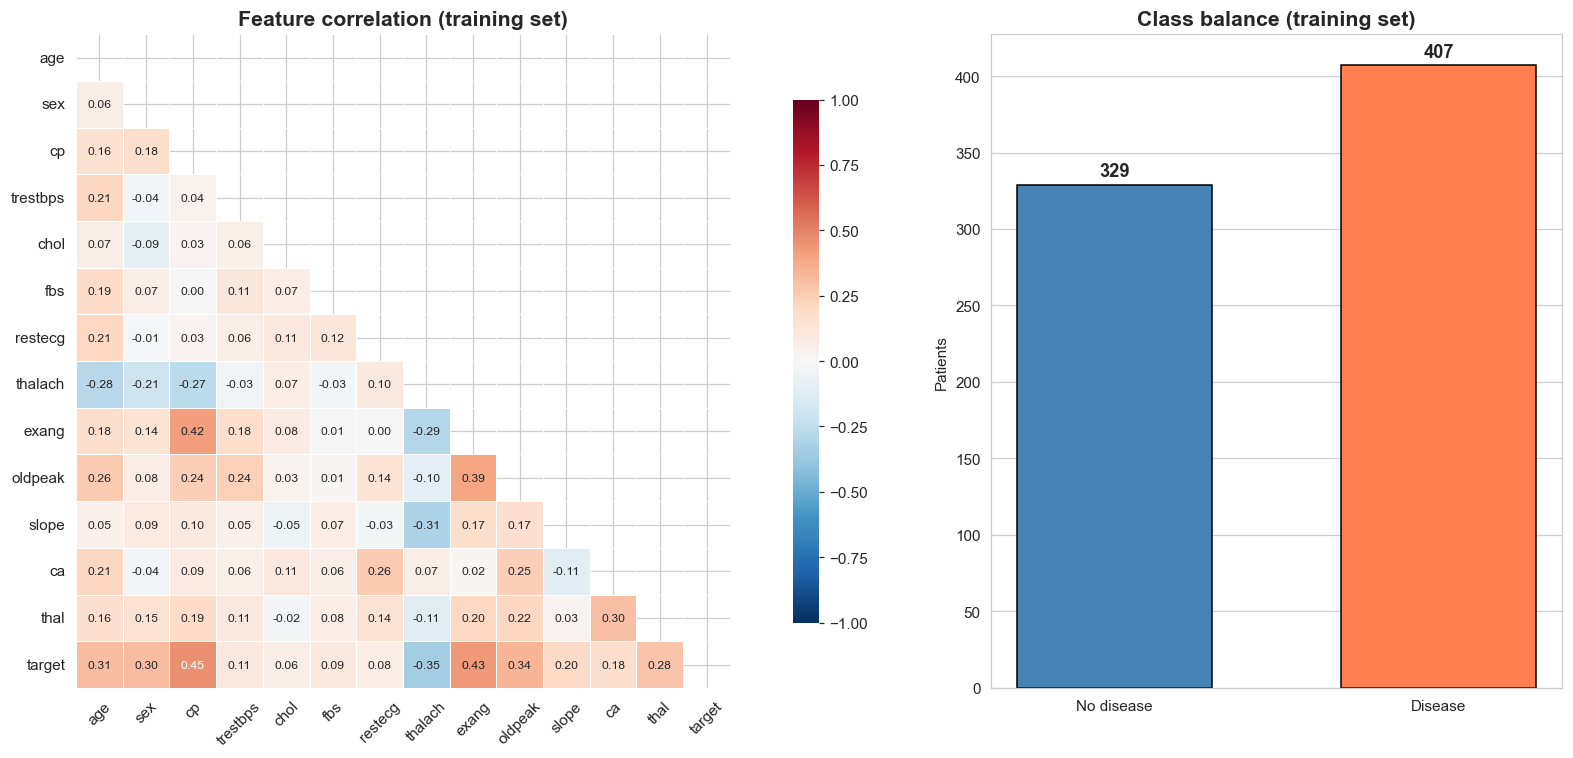

cp          0.454
exang       0.430
thalach    -0.349
oldpeak     0.339
age         0.308
sex         0.305
thal        0.283
slope       0.197
ca          0.180
trestbps    0.107
fbs         0.095
restecg     0.078
chol        0.064


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [2.2, 1]})

corr = train.corr()
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={'size': 8}, cbar_kws={'shrink': 0.8}, ax=axes[0])
axes[0].set_title('Feature correlation (training set)', fontsize=14, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

class_counts = train['target'].value_counts().sort_index()
bars = axes[1].bar(['No disease', 'Disease'], class_counts.values,
                   color=['steelblue', 'coral'], edgecolor='black', width=0.6)
axes[1].bar_label(bars, fontsize=12, fontweight='bold', padding=3)
axes[1].set_title('Class balance (training set)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Patients')
axes[1].grid(axis='x', visible=False)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'correlation_and_balance.png', bbox_inches='tight')
plt.show()

print(corr['target'].drop('target').sort_values(key=abs, ascending=False).round(3).to_string())

The strongest linear correlations with the target are the exercise-test variables (`cp`, `exang`,
`oldpeak`, `thalach`, `thal`). The classes are close to balanced (55% disease), so accuracy is a
reasonable headline metric here, though the reward analysis in section 11 argues for weighting
recall more heavily.

---
## 6. PCA and K-Means

Before supervised modelling, we check whether the patients separate into healthy and diseased
groups without using labels at all.

Both methods run on the **five continuous columns before discretisation**, standardised with
`StandardScaler`. Running them on the discretised integer bins would be meaningless: Euclidean
distance has no interpretation on category codes such as `thal` in {3, 6, 7}.

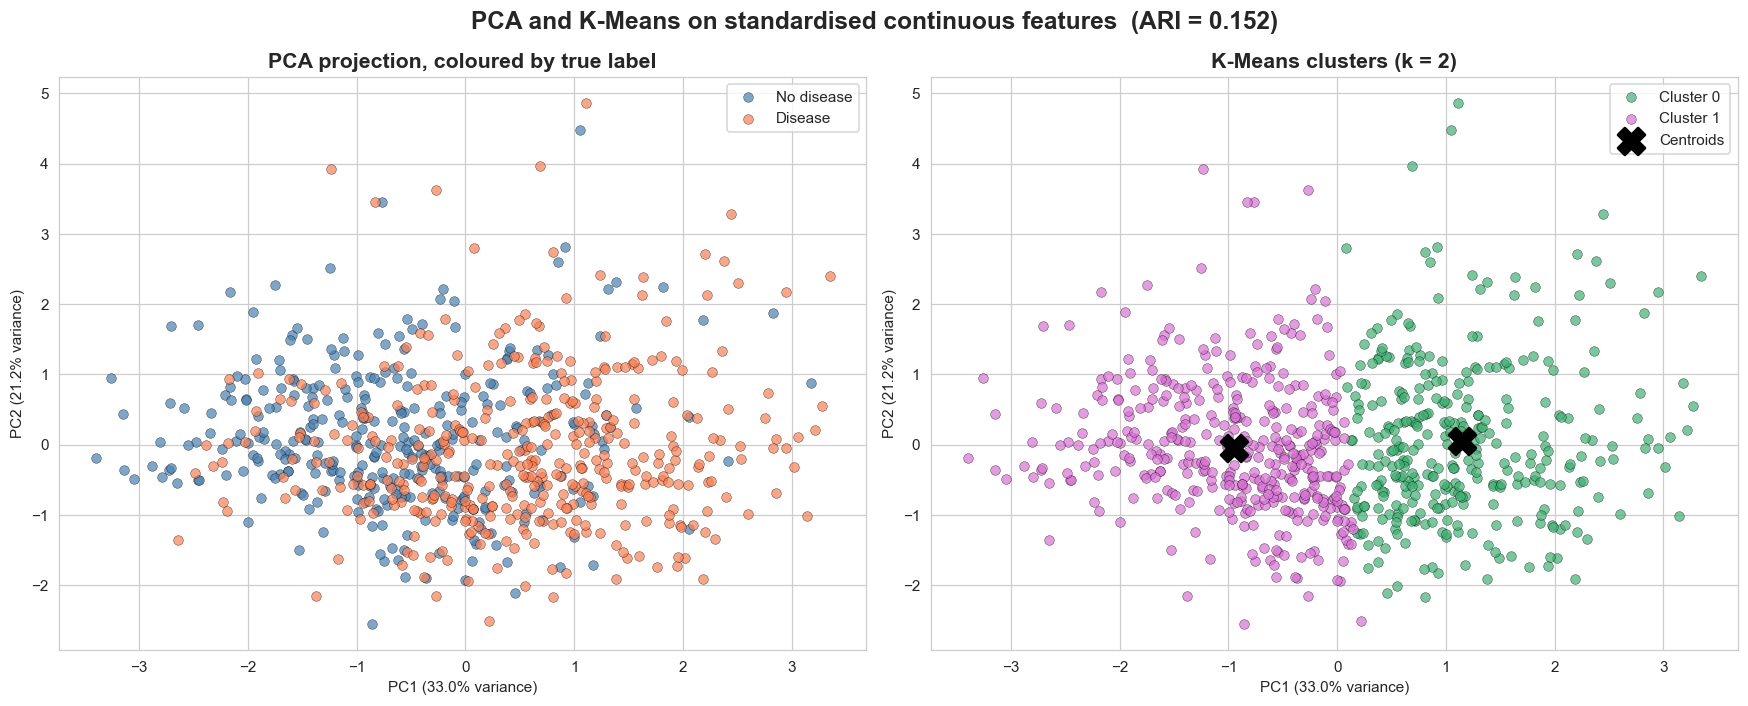

Explained variance: PC1 33.0%, PC2 21.2%, total 54.2%
Adjusted Rand Index of clusters vs true labels: 0.152


In [9]:
CONTINUOUS = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

scaler = StandardScaler().fit(train_filled[CONTINUOUS])
X_scaled = scaler.transform(train_filled[CONTINUOUS])

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

ari = adjusted_rand_score(y_train, cluster_labels)
pc1, pc2 = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

for label, color, name in [(0, 'steelblue', 'No disease'), (1, 'coral', 'Disease')]:
    m = y_train == label
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], c=color, s=40, alpha=0.7,
                    edgecolors='black', linewidths=0.3, label=name)
axes[0].set_title('PCA projection, coloured by true label', fontsize=14, fontweight='bold')

for cluster, color in [(0, 'mediumseagreen'), (1, 'orchid')]:
    m = cluster_labels == cluster
    axes[1].scatter(X_pca[m, 0], X_pca[m, 1], c=color, s=40, alpha=0.7,
                    edgecolors='black', linewidths=0.3, label=f'Cluster {cluster}')
axes[1].scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X',
                s=300, linewidths=2, label='Centroids')
axes[1].set_title('K-Means clusters (k = 2)', fontsize=14, fontweight='bold')

for ax in axes:
    ax.set_xlabel(f'PC1 ({pc1:.1%} variance)')
    ax.set_ylabel(f'PC2 ({pc2:.1%} variance)')
    ax.legend()

fig.suptitle(f'PCA and K-Means on standardised continuous features  (ARI = {ari:.3f})',
             fontsize=16, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'pca_kmeans.png', bbox_inches='tight')
plt.show()

print(f'Explained variance: PC1 {pc1:.1%}, PC2 {pc2:.1%}, total {pc1 + pc2:.1%}')
print(f'Adjusted Rand Index of clusters vs true labels: {ari:.3f}')

Two components retain about half the variance, and the ARI is near zero: the unsupervised clusters
do not line up with the disease labels. The continuous risk factors alone do not separate the
classes, which is why the labelled and probabilistic models in the next sections are needed.

---
## 7. Supervised Learning Models

Four baselines, all trained on the discretised training split and evaluated on the held-out test
split.

`CategoricalNB` needs zero-based contiguous category indices, so the features are re-indexed
against the declared codebook (`cp` {1,2,3,4} to {0,1,2,3}, `thal` {3,6,7} to {0,1,2}) and the
per-feature category counts are passed through `min_categories`. Without this, a category that
appears in the test set but not in the training set raises an error at prediction time.

The other three models receive the raw ordinal codes, as in the original project.

In [10]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }


CODE_INDEX = {c: {v: i for i, v in enumerate(STATE_NAMES[c])} for c in FEATURES}


def encode(df):
    return np.column_stack([df[c].map(CODE_INDEX[c]).values for c in FEATURES])


X_train_enc, X_test_enc = encode(train), encode(test)
min_categories = np.array([len(STATE_NAMES[c]) for c in FEATURES])

baselines = {
    'Logistic Regression': (LogisticRegression(max_iter=500, random_state=RANDOM_STATE),
                            X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
                      X_train, X_test),
    'Naive Bayes': (CategoricalNB(min_categories=min_categories),
                    X_train_enc, X_test_enc),
    'MLP Neural Net': (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                                     random_state=RANDOM_STATE, early_stopping=True),
                       X_train, X_test),
}

results, predictions = [], {}
for name, (model, fit_X, eval_X) in baselines.items():
    model.fit(fit_X, y_train)
    y_pred = model.predict(eval_X)
    y_prob = model.predict_proba(eval_X)[:, 1]
    results.append(evaluate(name, y_test, y_pred, y_prob))
    predictions[name] = y_pred
    print(f'  {name:<21} accuracy {results[-1]["Accuracy"]:.4f}'
          f'   ROC-AUC {results[-1]["ROC-AUC"]:.4f}')

  Logistic Regression   accuracy 0.7989   ROC-AUC 0.8782


  Random Forest         accuracy 0.7989   ROC-AUC 0.8812
  Naive Bayes           accuracy 0.8207   ROC-AUC 0.8918
  MLP Neural Net        accuracy 0.7446   ROC-AUC 0.8599


---
## 8. Bayesian Network Models

### 8.1 Domain-expert network

The edges are written by hand and follow a causal reading of the clinical picture: demographic
factors influence the physiological risk factors, those risk factors influence the underlying
disease, and the disease in turn produces the symptoms and abnormal test results we observe.

| Group | Edges | Reasoning |
|---|---|---|
| Demographics to risk factors | `age -> chol, trestbps, fbs`; `sex -> trestbps` | Cholesterol, blood pressure and blood sugar drift with age; blood pressure differs by sex |
| Risk factors to disease | `age, sex, chol, trestbps -> target` | Standard cardiovascular risk factors |
| Disease to observations | `target -> cp, exang, thalach, restecg, oldpeak, ca, thal` | The disease is what makes these tests come back abnormal |
| Test dependency | `oldpeak -> slope` | The ST segment slope depends on the degree of ST depression |

Parameters are fitted with a `BayesianEstimator` under a BDeu prior (equivalent sample size 10),
so rare parent configurations are smoothed instead of being assigned zero probability.

The full state space of every variable is passed to `fit` through `state_names`. Without it pgmpy
infers the states from the training data alone, and any state that happens to appear only in the
test split makes the corresponding query fail during evaluation.

In [11]:
DOMAIN_EDGES = [
    ('age', 'chol'), ('age', 'trestbps'), ('age', 'fbs'), ('sex', 'trestbps'),
    ('age', 'target'), ('sex', 'target'), ('chol', 'target'), ('trestbps', 'target'),
    ('target', 'cp'), ('target', 'exang'), ('target', 'thalach'), ('target', 'restecg'),
    ('target', 'oldpeak'), ('target', 'ca'), ('target', 'thal'),
    ('oldpeak', 'slope'),
]


def fit_bn(edges):
    bn = DiscreteBayesianNetwork(list(edges))
    bn.fit(train, estimator=BayesianEstimator, prior_type='BDeu',
           equivalent_sample_size=10, state_names=STATE_NAMES)
    return bn


domain_bn = fit_bn(DOMAIN_EDGES)
print(f'Domain BN: {len(domain_bn.nodes())} nodes, {len(domain_bn.edges())} edges')

Domain BN: 14 nodes, 16 edges


### 8.2 Structure learning with Hill Climbing and BIC

Hill Climbing starts from the empty graph and repeatedly applies the single edge addition, removal
or reversal that most improves the score, stopping when no local move helps.

The objective is the Bayesian Information Criterion:

$$\mathrm{BIC} = \log P(D \mid G, \hat{\theta}) - \frac{k}{2}\log N$$

The first term rewards fit to the data, and the second penalises the number of free parameters
$k$, which is what stops the search from simply adding every possible edge.

In [12]:
t0 = time.time()
hill_climb = HillClimbSearch(train)
learned_dag = hill_climb.estimate(scoring_method=BIC(train), max_iter=100, show_progress=False)
learned_bn = fit_bn(learned_dag.edges())

print(f'Learned in {time.time() - t0:.1f}s: '
      f'{len(learned_bn.nodes())} nodes, {len(learned_bn.edges())} edges')
for parent, child in learned_bn.edges():
    print(f'  {parent} -> {child}')

Learned in 1.3s: 14 nodes, 15 edges
  age -> fbs
  sex -> chol
  cp -> exang
  exang -> oldpeak
  thalach -> target
  thalach -> slope
  target -> cp
  target -> sex
  target -> age
  target -> thal
  target -> exang
  slope -> oldpeak
  oldpeak -> trestbps
  ca -> restecg
  thal -> ca


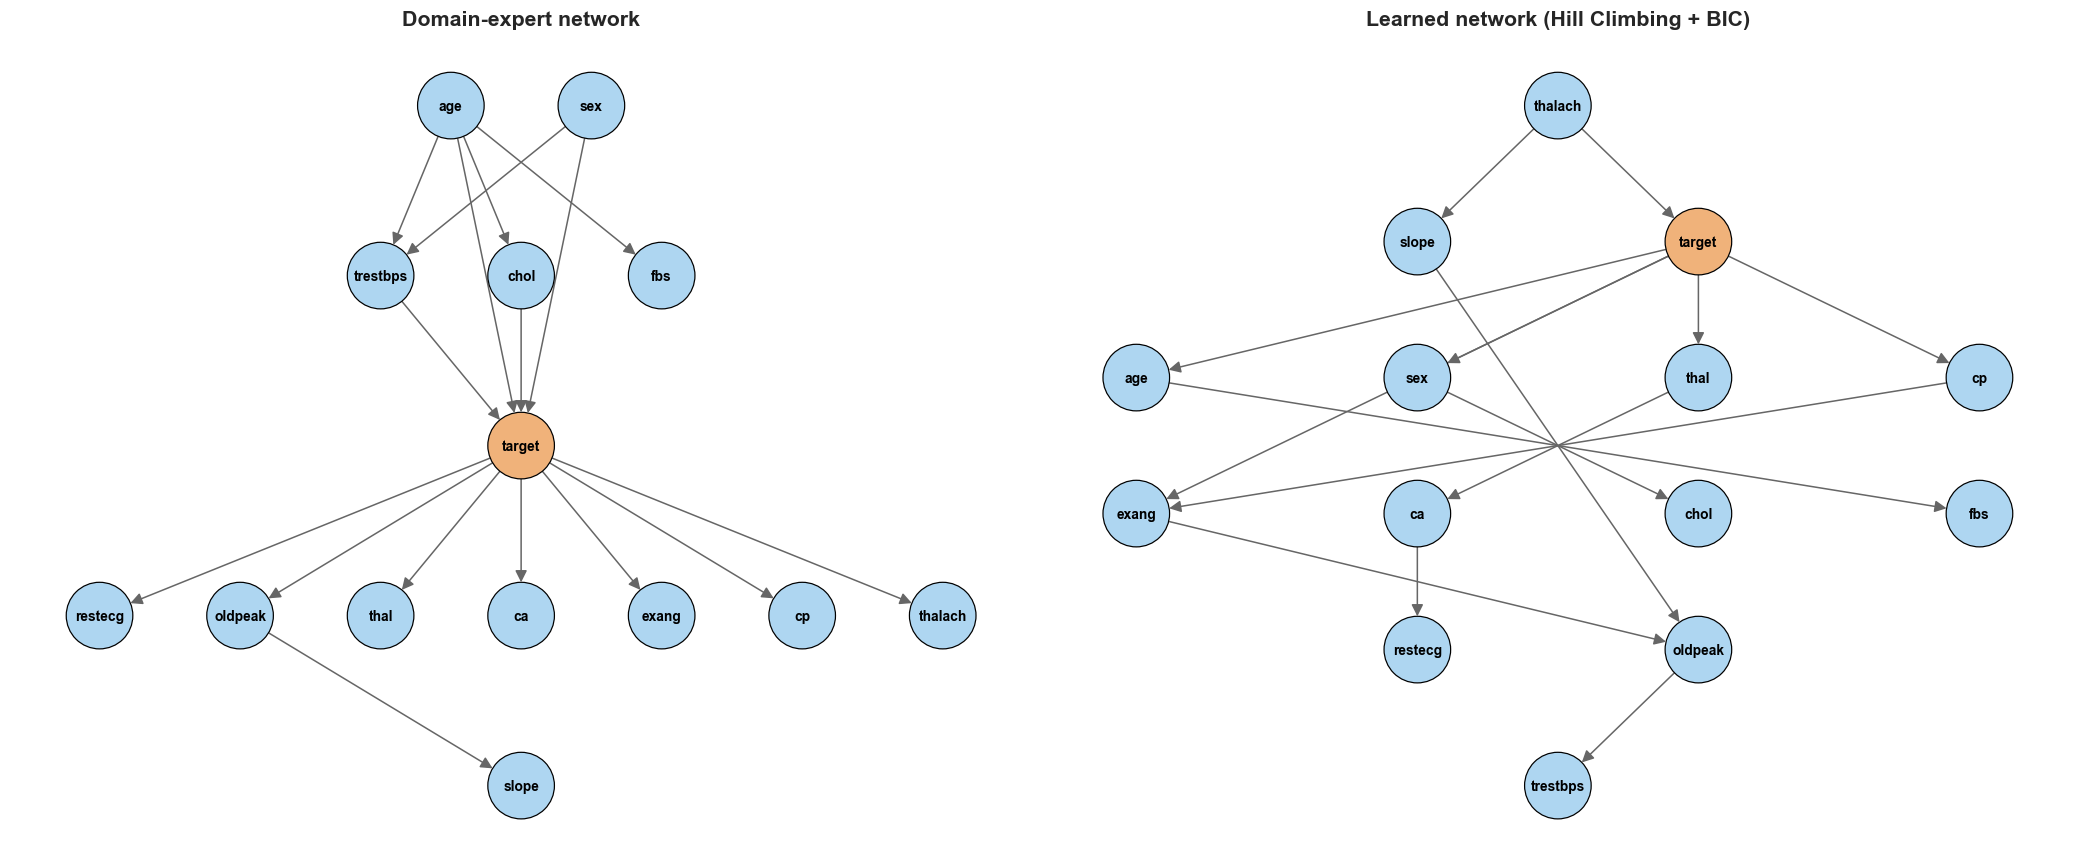

In [13]:
def draw_bn(model, title, ax):
    graph = nx.DiGraph(list(model.edges()))
    layers = {n: i for i, gen in enumerate(nx.topological_generations(graph)) for n in gen}
    nx.set_node_attributes(graph, layers, 'layer')
    pos = nx.multipartite_layout(graph, subset_key='layer', align='horizontal')
    pos = {n: (x, -y) for n, (x, y) in pos.items()}

    colors = ['#F0B27A' if n == 'target' else '#AED6F1' for n in graph.nodes()]
    nx.draw_networkx(graph, pos=pos, ax=ax, node_size=1900, node_color=colors,
                     font_size=9, font_weight='bold', arrows=True, arrowsize=16,
                     edge_color='#666666', edgecolors='black', linewidths=0.8)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(19, 8))
draw_bn(domain_bn, 'Domain-expert network', axes[0])
draw_bn(learned_bn, 'Learned network (Hill Climbing + BIC)', axes[1])
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'bn_structures.png', bbox_inches='tight')
plt.show()

In [14]:
for name, bn in [('Domain-expert', domain_bn), ('Learned', learned_bn)]:
    blanket = sorted(bn.get_markov_blanket('target'))
    outside = sorted(set(FEATURES) - set(blanket))
    print(f'{name} BN, Markov blanket of target ({len(blanket)}): {blanket}')
    print(f'    conditionally independent of target given that blanket: {outside}\n')

Domain-expert BN, Markov blanket of target (11): ['age', 'ca', 'chol', 'cp', 'exang', 'oldpeak', 'restecg', 'sex', 'thal', 'thalach', 'trestbps']
    conditionally independent of target given that blanket: ['fbs', 'slope']

Learned BN, Markov blanket of target (6): ['age', 'cp', 'exang', 'sex', 'thal', 'thalach']
    conditionally independent of target given that blanket: ['ca', 'chol', 'fbs', 'oldpeak', 'restecg', 'slope', 'trestbps']



The Markov blanket is the set of variables that render `target` independent of everything else. In
the domain network only `fbs` and `slope` fall outside it. The learned network is much sparser:
once `age, cp, exang, sex, thal, thalach` are observed, no other feature changes `P(target)` at
all. That fact reappears in section 11, where the sequential procedure runs out of informative
tests after a handful of steps.

---
## 9. Probabilistic Inference

### 9.1 Exact inference with Variable Elimination

Variable Elimination computes the exact posterior by summing the joint distribution over the
variables that are neither queried nor observed, reusing intermediate factors instead of
enumerating the full joint table.

The whole test set is classified by querying `P(target | all 13 features)` per patient. Because
the state space was declared up front, every query succeeds; the counter below is there to make
any failure visible rather than silently substituting a default probability.

In [15]:
ve_domain = VariableElimination(domain_bn)
ve_learned = VariableElimination(learned_bn)


def p_disease(engine, evidence):
    factor = engine.query(['target'], evidence=evidence, show_progress=False)
    return float(factor.values[factor.state_names['target'].index(1)])


def bn_predict(engine, df, threshold=0.5):
    probs, failures = [], 0
    for _, row in df.iterrows():
        evidence = {f: int(row[f]) for f in FEATURES}
        try:
            probs.append(p_disease(engine, evidence))
        except Exception:
            failures += 1
            probs.append(float(train['target'].mean()))
    probs = np.array(probs)
    return (probs >= threshold).astype(int), probs, failures


bn_probs = {}
for name, engine in [('Domain Expert BN', ve_domain), ('BN Hill Climb + BIC', ve_learned)]:
    y_pred, y_prob, failures = bn_predict(engine, test)
    results.append(evaluate(name, y_test, y_pred, y_prob))
    predictions[name] = y_pred
    bn_probs[name] = y_prob
    print(f'  {name:<21} accuracy {results[-1]["Accuracy"]:.4f}'
          f'   ROC-AUC {results[-1]["ROC-AUC"]:.4f}   failed queries {failures}')

  Domain Expert BN      accuracy 0.7935   ROC-AUC 0.8850   failed queries 0
  BN Hill Climb + BIC   accuracy 0.7989   ROC-AUC 0.8879   failed queries 0


### 9.2 Inference from partial evidence

This is the property that the ordinary classifiers do not have. The same fitted network is queried
with progressively more of a patient's record, mimicking how information actually arrives in a
clinic: demographics first, then the consultation, then the exercise test, then the full workup.

Two views are shown. The left panel follows two individual patients, picked by a fixed rule
(the first test-set patient of each class) rather than selected to look convincing. The right
panel is the one that actually establishes the point: the mean posterior across **all 184 test
patients**,
split by their true label, at each evidence stage. If partial-evidence inference works, the two
curves should separate as evidence accumulates.

In [16]:
EVIDENCE_STAGES = [
    ('Demographics', ['age', 'sex']),
    ('+ Consultation', ['age', 'sex', 'cp', 'trestbps', 'chol']),
    ('+ Exercise test', ['age', 'sex', 'cp', 'trestbps', 'chol', 'exang', 'oldpeak', 'thalach']),
    ('Full record', FEATURES),
]

demo_patients = {
    'Patient A (true: disease)': test[test['target'] == 1].iloc[0],
    'Patient B (true: no disease)': test[test['target'] == 0].iloc[0],
}

trajectories = {}
for label, patient in demo_patients.items():
    row = []
    for stage, feats in EVIDENCE_STAGES:
        row.append(p_disease(ve_learned, {f: int(patient[f]) for f in feats}))
    trajectories[label] = row

stage_posteriors = np.array([
    [p_disease(ve_learned, {f: int(row[f]) for f in feats}) for _, row in test.iterrows()]
    for _, feats in EVIDENCE_STAGES
])

stage_summary = pd.DataFrame({
    'stage': [s for s, _ in EVIDENCE_STAGES],
    'n_evidence': [len(f) for _, f in EVIDENCE_STAGES],
    'mean P(disease) | true=1': stage_posteriors[:, y_test == 1].mean(axis=1).round(4),
    'mean P(disease) | true=0': stage_posteriors[:, y_test == 0].mean(axis=1).round(4),
    'test accuracy @0.5': [(  (stage_posteriors[i] >= 0.5).astype(int) == y_test).mean().round(4)
                           for i in range(len(EVIDENCE_STAGES))],
    'ROC-AUC': [round(roc_auc_score(y_test, stage_posteriors[i]), 4)
                for i in range(len(EVIDENCE_STAGES))],
})
stage_summary

,stage,n_evidence,mean P(disease) | true=1,mean P(disease) | true=0,test accuracy @0.5,ROC-AUC
0,Demographics,2,0.6093,0.4755,0.6576,0.6774
1,+ Consultation,5,0.7398,0.3507,0.8043,0.8620
2,+ Exercise test,8,0.7593,0.2978,0.7880,0.8785
3,Full record,13,0.7684,0.2764,0.7989,0.8879


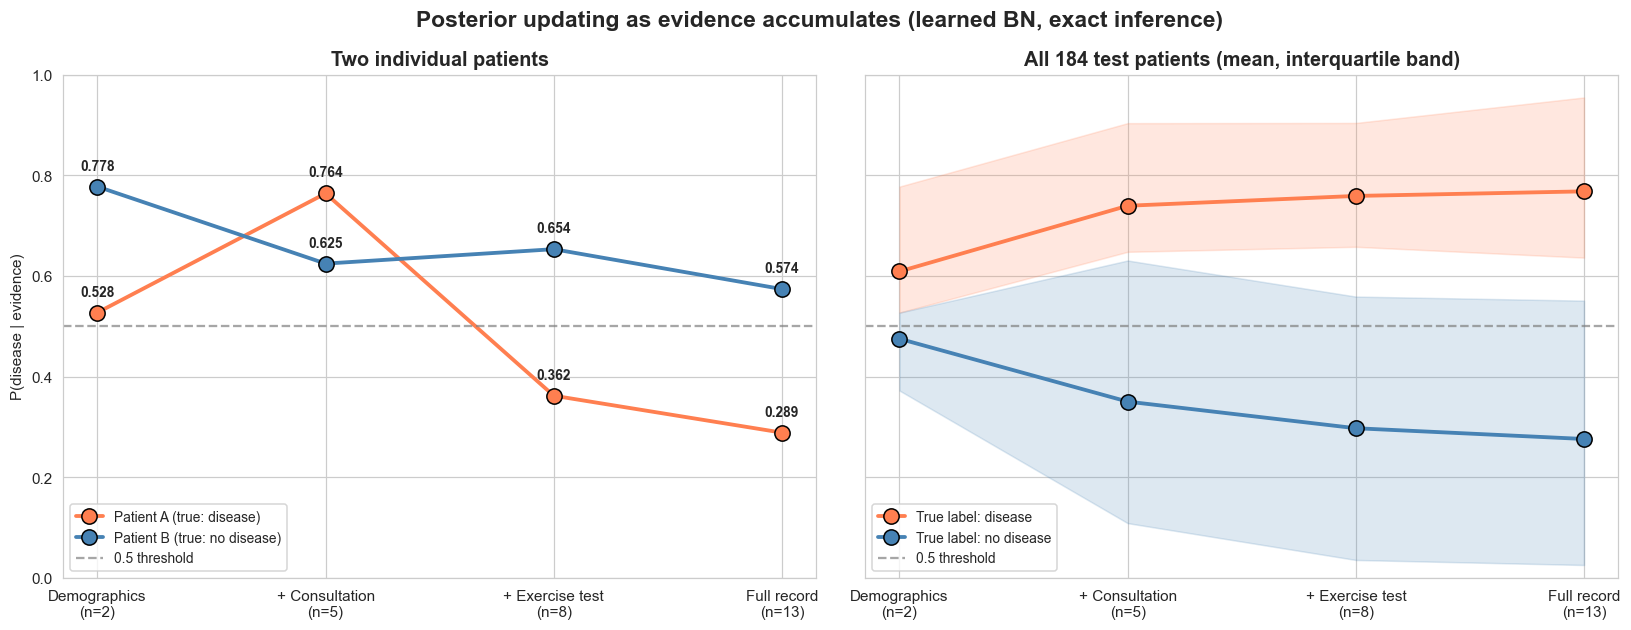

In [17]:
x = np.arange(len(EVIDENCE_STAGES))
stage_labels = [f'{s}\n(n={len(f)})' for s, f in EVIDENCE_STAGES]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharey=True)

for (label, values), color in zip(trajectories.items(), ['coral', 'steelblue']):
    axes[0].plot(x, values, 'o-', color=color, linewidth=2.5, markersize=10,
                 markeredgecolor='black', label=label)
    for xi, v in zip(x, values):
        axes[0].annotate(f'{v:.3f}', (xi, v), textcoords='offset points',
                         xytext=(0, 11), ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Two individual patients', fontsize=13, fontweight='bold')

for label, mask, color in [('True label: disease', y_test == 1, 'coral'),
                           ('True label: no disease', y_test == 0, 'steelblue')]:
    means = stage_posteriors[:, mask].mean(axis=1)
    q1 = np.percentile(stage_posteriors[:, mask], 25, axis=1)
    q3 = np.percentile(stage_posteriors[:, mask], 75, axis=1)
    axes[1].plot(x, means, 'o-', color=color, linewidth=2.5, markersize=10,
                 markeredgecolor='black', label=label)
    axes[1].fill_between(x, q1, q3, color=color, alpha=0.18)
axes[1].set_title('All 184 test patients (mean, interquartile band)',
                  fontsize=13, fontweight='bold')

for ax in axes:
    ax.axhline(0.5, color='gray', linestyle='--', alpha=0.7, label='0.5 threshold')
    ax.set_xticks(x)
    ax.set_xticklabels(stage_labels)
    ax.set_ylim(0, 1)
    ax.legend(loc='lower left', fontsize=9)
axes[0].set_ylabel('P(disease | evidence)')

fig.suptitle('Posterior updating as evidence accumulates (learned BN, exact inference)',
             fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'inference_demo.png', bbox_inches='tight')
plt.show()

The right panel is the result that matters. Averaged over the whole test set the two groups start
close to the prior and separate steadily as evidence arrives, and ROC-AUC rises at every stage in
the table above. The network returns a usable probability at every stage, not only once the record
is complete, which is the property none of the four baselines have.

The left panel is a corrective against reading too much into single cases. Both of these patients
are ones the model gets wrong at a 0.5 threshold: Patient A's exercise-test results pull the
posterior down below 0.5 even though disease is present, and Patient B ends just above it. They
were picked by a fixed rule rather than chosen to look convincing, and individual trajectories are
noisy even where the aggregate behaviour is sound.

### 9.3 Approximate inference with Likelihood Weighting

Likelihood Weighting samples the non-evidence variables in topological order while clamping the
evidence variables to their observed values, and weights each sample by the likelihood of that
evidence. The estimate is the **weighted** mean, not the plain mean. Dropping the weights would
turn the method into unconditioned forward sampling and bias the answer.

Correctness is checked against the exact Variable Elimination answer for the same query, which is
the meaningful test: the estimate should converge on the exact posterior as the sample count
grows.

In [18]:
sampler = BayesianModelSampling(learned_bn)
lw_patient = demo_patients['Patient A (true: disease)']
lw_evidence = {f: int(lw_patient[f]) for f in ['age', 'sex', 'cp', 'trestbps', 'chol']}
exact_posterior = p_disease(ve_learned, lw_evidence)

sample_sizes = [100, 250, 500, 1000, 2500, 5000, 10000, 20000]
lw_estimates = []
for n in sample_sizes:
    samples = sampler.likelihood_weighted_sample(
        evidence=[State(var, val) for var, val in lw_evidence.items()],
        size=n, show_progress=False, seed=RANDOM_STATE,
    )
    weights = samples['_weight'].to_numpy()
    lw_estimates.append(float((samples['target'].to_numpy() * weights).sum() / weights.sum()))

lw_df = pd.DataFrame({
    'samples': sample_sizes,
    'LW estimate': np.round(lw_estimates, 4),
    'absolute error': np.round(np.abs(np.array(lw_estimates) - exact_posterior), 4),
})
print(f'Evidence: {lw_evidence}')
print(f'Exact P(disease | evidence) via Variable Elimination: {exact_posterior:.4f}\n')
print(lw_df.to_string(index=False))

Evidence: {'age': 1, 'sex': 1, 'cp': 4, 'trestbps': 1, 'chol': 1}
Exact P(disease | evidence) via Variable Elimination: 0.7643

 samples  LW estimate  absolute error
     100       0.7540          0.0103
     250       0.7796          0.0153
     500       0.7444          0.0199
    1000       0.7767          0.0123
    2500       0.7614          0.0029
    5000       0.7589          0.0055
   10000       0.7715          0.0072
   20000       0.7640          0.0003


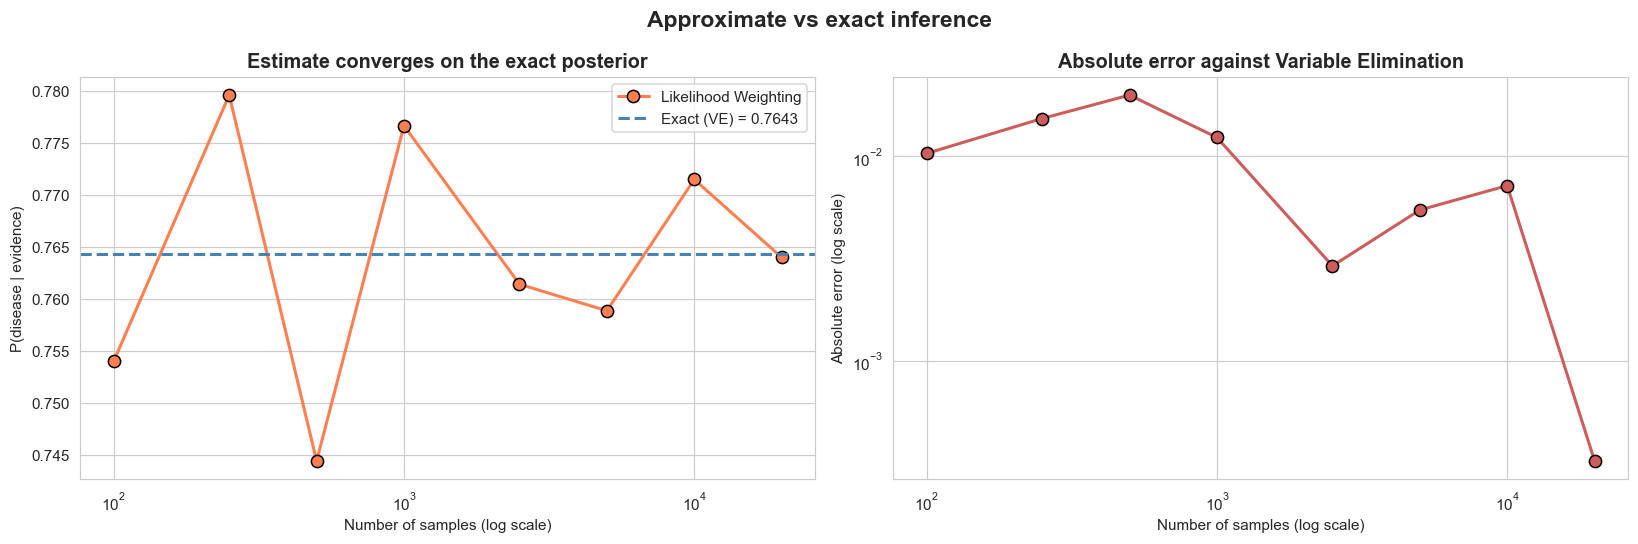

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(sample_sizes, lw_estimates, 'o-', color='coral', linewidth=2,
             markersize=8, markeredgecolor='black', label='Likelihood Weighting')
axes[0].axhline(exact_posterior, color='steelblue', linestyle='--', linewidth=2,
                label=f'Exact (VE) = {exact_posterior:.4f}')
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of samples (log scale)')
axes[0].set_ylabel('P(disease | evidence)')
axes[0].set_title('Estimate converges on the exact posterior', fontsize=13, fontweight='bold')
axes[0].legend()

errors = np.abs(np.array(lw_estimates) - exact_posterior)
axes[1].plot(sample_sizes, errors, 'o-', color='indianred', linewidth=2,
             markersize=8, markeredgecolor='black')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Number of samples (log scale)')
axes[1].set_ylabel('Absolute error (log scale)')
axes[1].set_title('Absolute error against Variable Elimination',
                  fontsize=13, fontweight='bold')

fig.suptitle('Approximate vs exact inference', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'approx_vs_exact.png', bbox_inches='tight')
plt.show()

The sampled estimate is within roughly 0.02 of the exact value even at 100 samples and closes to
about 0.0002 at 20,000. The error does not fall monotonically, which is expected for a stochastic
estimator, but the trend follows the usual Monte Carlo behaviour.

---
## 10. Value of Perfect Information

Given what is already known about a patient, which test is worth ordering next? Two related
quantities are computed for every unobserved feature `X`, both by exact inference.

**Expected information gain** is the mutual information between the feature and the diagnosis,
in bits: how much observing `X` is expected to reduce uncertainty about `target`.

$$\mathrm{IG}(X) = H(T \mid e) - \sum_{x} P(X = x \mid e)\, H(T \mid e, X = x)$$

**Value of Perfect Information** is the decision-theoretic quantity, measured in units of the
reward matrix below. It is the expected gain in utility from observing `X` before deciding, and it
is zero whenever knowing `X` would not change the decision that gets made:

$$\mathrm{VPI}(X) = \sum_{x} P(X = x \mid e) \max_{a} EU(a \mid e, X = x) - \max_{a} EU(a \mid e)$$

### Reward matrix

The two are different because a test can be informative without being decision-relevant. The
rewards encode the asymmetry of the clinical error costs.

| Outcome | Reward | Rationale |
|---|---|---|
| True positive | +5 | Disease found, treatment can start |
| True negative | +2 | Patient correctly cleared |
| False positive | -1 | Unnecessary follow-up, but recoverable |
| False negative | -10 | Missed disease, the most damaging error |

These weights are our own choice, not values taken from any clinical guideline.

In [20]:
REWARDS = {(1, 1): 5, (0, 0): 2, (0, 1): -1, (1, 0): -10}


def expected_utility(p, action):
    return p * REWARDS[(1, action)] + (1 - p) * REWARDS[(0, action)]


def best_action(p):
    return 1 if expected_utility(p, 1) >= expected_utility(p, 0) else 0


def binary_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-(p * np.log2(p) + (1 - p) * np.log2(1 - p)))


def value_of_information(engine, evidence, candidates):
    p_now = p_disease(engine, evidence)
    h_now = binary_entropy(p_now)
    eu_now = max(expected_utility(p_now, 0), expected_utility(p_now, 1))

    rows = []
    for feature in candidates:
        marginal = engine.query([feature], evidence=evidence, show_progress=False)
        h_after, eu_after = 0.0, 0.0
        for state, weight in zip(marginal.state_names[feature], marginal.values):
            if weight < 1e-12:
                continue
            p_state = p_disease(engine, {**evidence, feature: state})
            h_after += weight * binary_entropy(p_state)
            eu_after += weight * max(expected_utility(p_state, 0), expected_utility(p_state, 1))
        rows.append({
            'feature': feature,
            'info_gain_bits': max(0.0, h_now - h_after),
            'vpi': max(0.0, eu_after - eu_now),
        })

    return (pd.DataFrame(rows)
            .sort_values('info_gain_bits', ascending=False)
            .reset_index(drop=True))

In [21]:
decision_threshold = (
    (REWARDS[(0, 0)] - REWARDS[(0, 1)])
    / ((REWARDS[(1, 1)] - REWARDS[(1, 0)]) + (REWARDS[(0, 0)] - REWARDS[(0, 1)]))
)
print(f'Utility-optimal decision threshold: {decision_threshold:.4f}')

start_patient = demo_patients['Patient A (true: disease)']
start_evidence = {'age': int(start_patient['age']), 'sex': int(start_patient['sex'])}
voi = value_of_information(ve_learned, start_evidence,
                           [f for f in FEATURES if f not in start_evidence])

print(f'\nStarting evidence: {start_evidence}')
print(f'P(disease | evidence) = {p_disease(ve_learned, start_evidence):.4f}\n')
print(voi.round(4).to_string(index=False))

Utility-optimal decision threshold: 0.1667

Starting evidence: {'age': 1, 'sex': 1}
P(disease | evidence) = 0.5275

 feature  info_gain_bits    vpi
      cp          0.2005 0.0787
   exang          0.1397 0.0000
 thalach          0.0927 0.0000
    thal          0.0592 0.0000
 oldpeak          0.0181 0.0000
   slope          0.0119 0.0000
      ca          0.0057 0.0000
trestbps          0.0008 0.0000
 restecg          0.0007 0.0000
    chol          0.0000 0.0000
     fbs          0.0000 0.0000


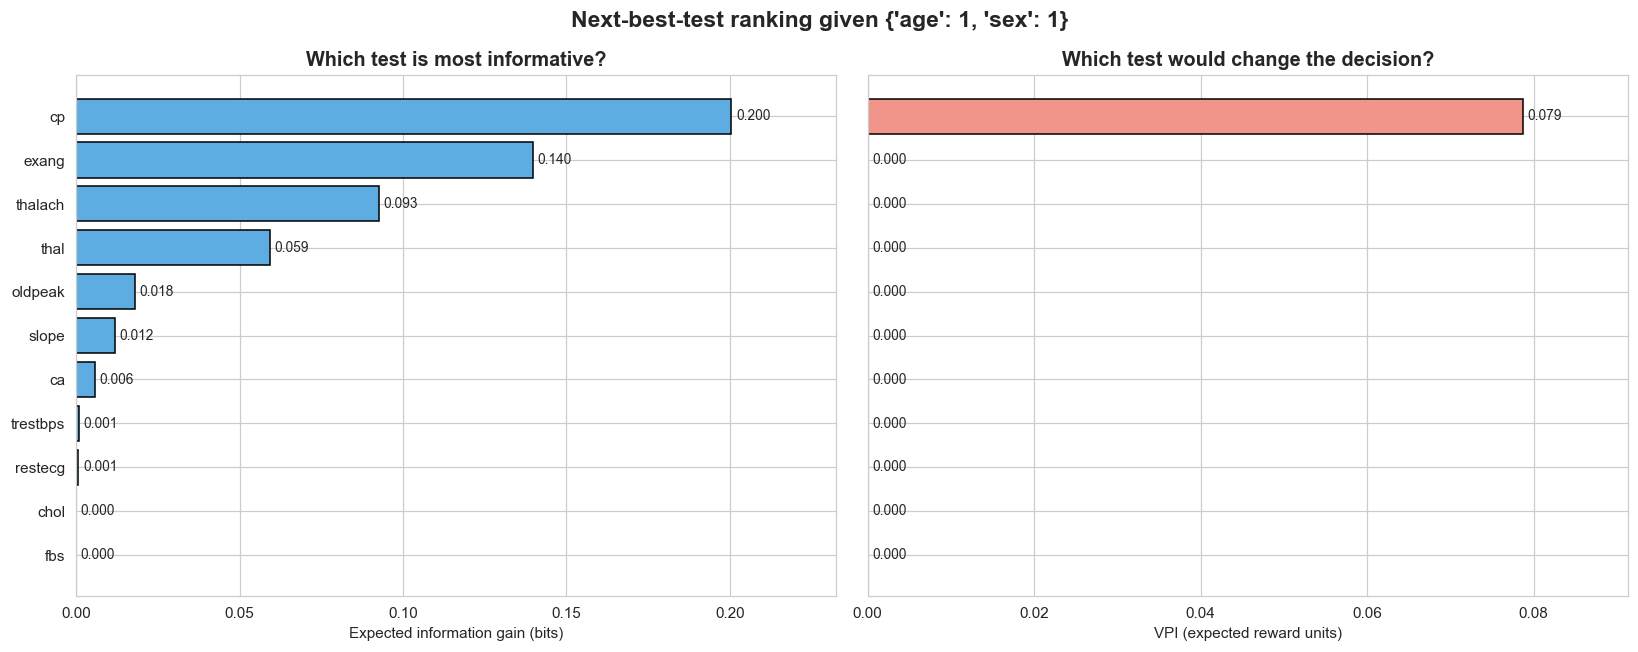

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].barh(voi['feature'], voi['info_gain_bits'], color='#5DADE2', edgecolor='black')
axes[0].set_xlabel('Expected information gain (bits)')
axes[0].set_title('Which test is most informative?', fontsize=13, fontweight='bold')
axes[0].bar_label(axes[0].containers[0], fmt='%.3f', fontsize=9, padding=3)

axes[1].barh(voi['feature'], voi['vpi'], color='#F1948A', edgecolor='black')
axes[1].set_xlabel('VPI (expected reward units)')
axes[1].set_title('Which test would change the decision?', fontsize=13, fontweight='bold')
axes[1].bar_label(axes[1].containers[0], fmt='%.3f', fontsize=9, padding=3)

axes[0].invert_yaxis()
for ax in axes:
    ax.margins(x=0.16)

fig.suptitle(f'Next-best-test ranking given {start_evidence}', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'vpi_ranking.png', bbox_inches='tight')
plt.show()

The two rankings say different things, and the gap between them is the point of this section.
Several features carry real information about the diagnosis, but only `cp` has non-zero VPI: it is
the only test whose result could flip the decision away from the one that would already be taken.
Every other test would be paid for without changing what happens to the patient.

---
## 11. Sequential Diagnosis

Diagnosis is treated as a sequence of decisions. The state is the set of results observed so far,
the action is which test to order next, and the procedure stops when the next test would be
uninformative.

Tests are chosen greedily by expected information gain. This is a myopic, one-step-lookahead
policy rather than a solved MDP: no transition model is optimised over, and no lookahead beyond
the immediate next test is performed.

### Decision threshold

The original version of this project applied the reward matrix while still calling a patient
positive at `P(disease) >= 0.5`. Those two choices are inconsistent. Under the rewards above, the
break-even probability is

$$P^* = \frac{R_{TN} - R_{FP}}{(R_{TP} - R_{FN}) + (R_{TN} - R_{FP})} = \frac{2 - (-1)}{(5 - (-10)) + (2 - (-1))} = \frac{3}{18} = 0.167$$

so the utility-maximising rule commits to "disease" far earlier than a 0.5 cut-off would. That is
the intended consequence of penalising a missed diagnosis ten times more than a false alarm.

In [23]:
def sequential_diagnosis(engine, patient, max_steps=6, start=('age', 'sex'), min_gain=1e-4):
    observed = list(start)
    evidence = {f: int(patient[f]) for f in observed}
    true_label = int(patient['target'])
    history = []

    for step in range(max_steps + 1):
        p = p_disease(engine, evidence)
        action = best_action(p)
        history.append({
            'step': step,
            'test_ordered': '-' if step == 0 else observed[-1],
            'n_observed': len(observed),
            'p_disease': round(p, 4),
            'decision': action,
            'reward': REWARDS[(true_label, action)],
        })

        remaining = [f for f in FEATURES if f not in evidence]
        if step == max_steps or not remaining:
            break
        ranking = value_of_information(engine, evidence, remaining)
        if ranking.iloc[0]['info_gain_bits'] < min_gain:
            print(f'  stopped after step {step}: no remaining test carries information')
            break
        next_test = ranking.iloc[0]['feature']
        observed.append(next_test)
        evidence[next_test] = int(patient[next_test])

    return pd.DataFrame(history)


diagnosis_runs = {}
for label, patient in demo_patients.items():
    print(f'{label}')
    run = sequential_diagnosis(ve_learned, patient)
    diagnosis_runs[label] = run
    print(run.to_string(index=False))
    print(f'  total reward: {run["reward"].sum()}\n')

Patient A (true: disease)
  stopped after step 4: no remaining test carries information
 step test_ordered  n_observed  p_disease  decision  reward
    0            -           2     0.5275         1       5
    1           cp           3     0.7618         1       5
    2      thalach           4     0.5198         1       5
    3        exang           5     0.3624         1       5
    4         thal           6     0.2890         1       5
  total reward: 25

Patient B (true: no disease)


  stopped after step 4: no remaining test carries information
 step test_ordered  n_observed  p_disease  decision  reward
    0            -           2     0.7779         1      -1
    1           cp           3     0.6341         1      -1
    2      thalach           4     0.7167         1      -1
    3         thal           5     0.6440         1      -1
    4        exang           6     0.5743         1      -1
  total reward: -5



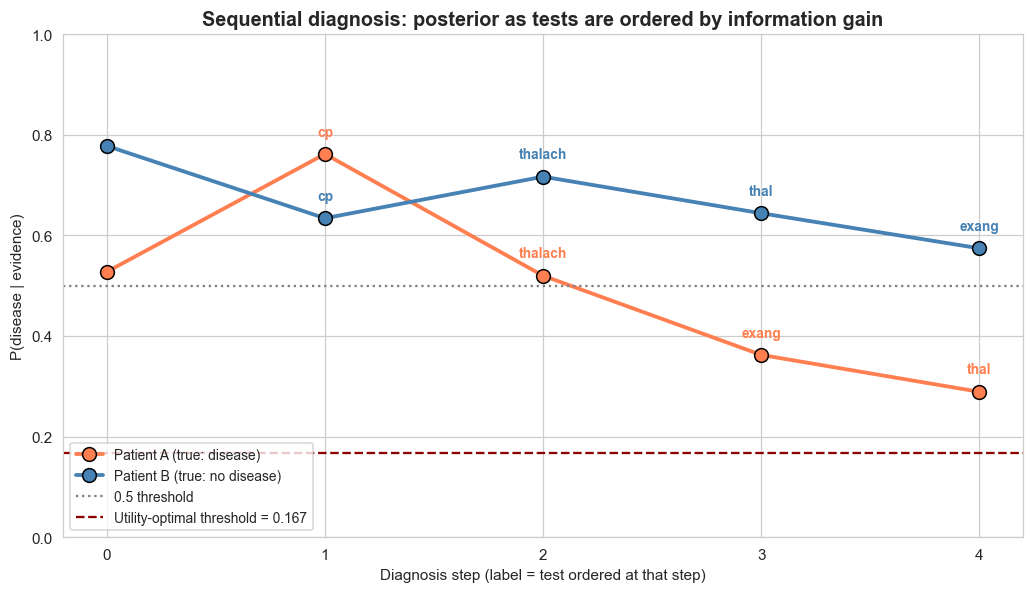

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))

for (label, run), color in zip(diagnosis_runs.items(), ['coral', 'steelblue']):
    ax.plot(run['step'], run['p_disease'], 'o-', color=color, linewidth=2.5,
            markersize=9, markeredgecolor='black', label=label)
    for _, r in run.iterrows():
        if r['step'] > 0:
            ax.annotate(r['test_ordered'], (r['step'], r['p_disease']),
                        textcoords='offset points', xytext=(0, 12),
                        ha='center', fontsize=9, fontweight='bold', color=color)

ax.axhline(0.5, color='gray', linestyle=':', label='0.5 threshold')
ax.axhline(decision_threshold, color='darkred', linestyle='--',
           label=f'Utility-optimal threshold = {decision_threshold:.3f}')
ax.set_xlabel('Diagnosis step (label = test ordered at that step)')
ax.set_ylabel('P(disease | evidence)')
ax.set_ylim(0, 1)
ax.set_xticks(sorted({s for run in diagnosis_runs.values() for s in run['step']}))
ax.set_title('Sequential diagnosis: posterior as tests are ordered by information gain',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower left', fontsize=9)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'sequential_diagnosis.png', bbox_inches='tight')
plt.show()

In [25]:
threshold_rows = []
for label, probs in bn_probs.items():
    for name, thr in [('0.5 (accuracy-oriented)', 0.5),
                      (f'{decision_threshold:.3f} (utility-optimal)', decision_threshold)]:
        pred = (probs >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        total_reward = sum(REWARDS[(int(a), int(b))] for a, b in zip(y_test, pred))
        threshold_rows.append({
            'Model': label, 'Threshold': name,
            'Accuracy': round(accuracy_score(y_test, pred), 4),
            'Recall': round(recall_score(y_test, pred), 4),
            'Precision': round(precision_score(y_test, pred), 4),
            'FN': fn, 'FP': fp,
            'Total reward': total_reward,
            'Reward/patient': round(total_reward / len(y_test), 3),
        })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df

,Model,Threshold,Accuracy,Recall,Precision,FN,FP,Total reward,Reward/patient
0,Domain Expert BN,0.5 (accuracy-oriented),0.7935,0.7941,0.8265,21,17,308,1.674
1,Domain Expert BN,0.167 (utility-optimal),0.7989,0.9118,0.7686,9,28,455,2.473
2,BN Hill Climb + BIC,0.5 (accuracy-oriented),0.7989,0.8529,0.7982,15,22,383,2.082
3,BN Hill Climb + BIC,0.167 (utility-optimal),0.7609,0.9510,0.7132,5,39,482,2.620


Moving to the utility-optimal threshold roughly halves the false negatives on both networks (21 to
9, and 15 to 5) and raises total reward, which is what the reward matrix asks for. It costs
precision in both cases. Accuracy behaves differently for the two networks, dropping for the
learned BN (0.7989 to 0.7609) but edging up for the domain BN (0.7935 to 0.7989), so the shift
is not a straight accuracy-for-recall trade and should not be described as one.

Whether this is the right operating point depends entirely on the reward numbers, which we chose
ourselves. The transferable point is narrower: once a reward matrix is written down, the threshold
follows from it, and leaving the threshold at 0.5 while quoting asymmetric costs is inconsistent.

The accuracy, precision, recall, F1 and ROC-AUC figures reported everywhere else in this notebook
use the conventional 0.5 threshold, so that all six models are compared on the same basis.

---
## 12. Model Evaluation

All six models on the same held-out test set (184 patients), at the conventional 0.5 threshold.

In [26]:
results_df = pd.DataFrame(results).round(4)
results_df.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Naive Bayes,0.8207,0.8416,0.8333,0.8374,0.8918
1,BN Hill Climb + BIC,0.7989,0.7982,0.8529,0.8246,0.8879
2,Domain Expert BN,0.7935,0.8265,0.7941,0.8100,0.8850
3,Random Forest,0.7989,0.8095,0.8333,0.8213,0.8812
4,Logistic Regression,0.7989,0.7982,0.8529,0.8246,0.8782
5,MLP Neural Net,0.7446,0.7477,0.8137,0.7793,0.8599


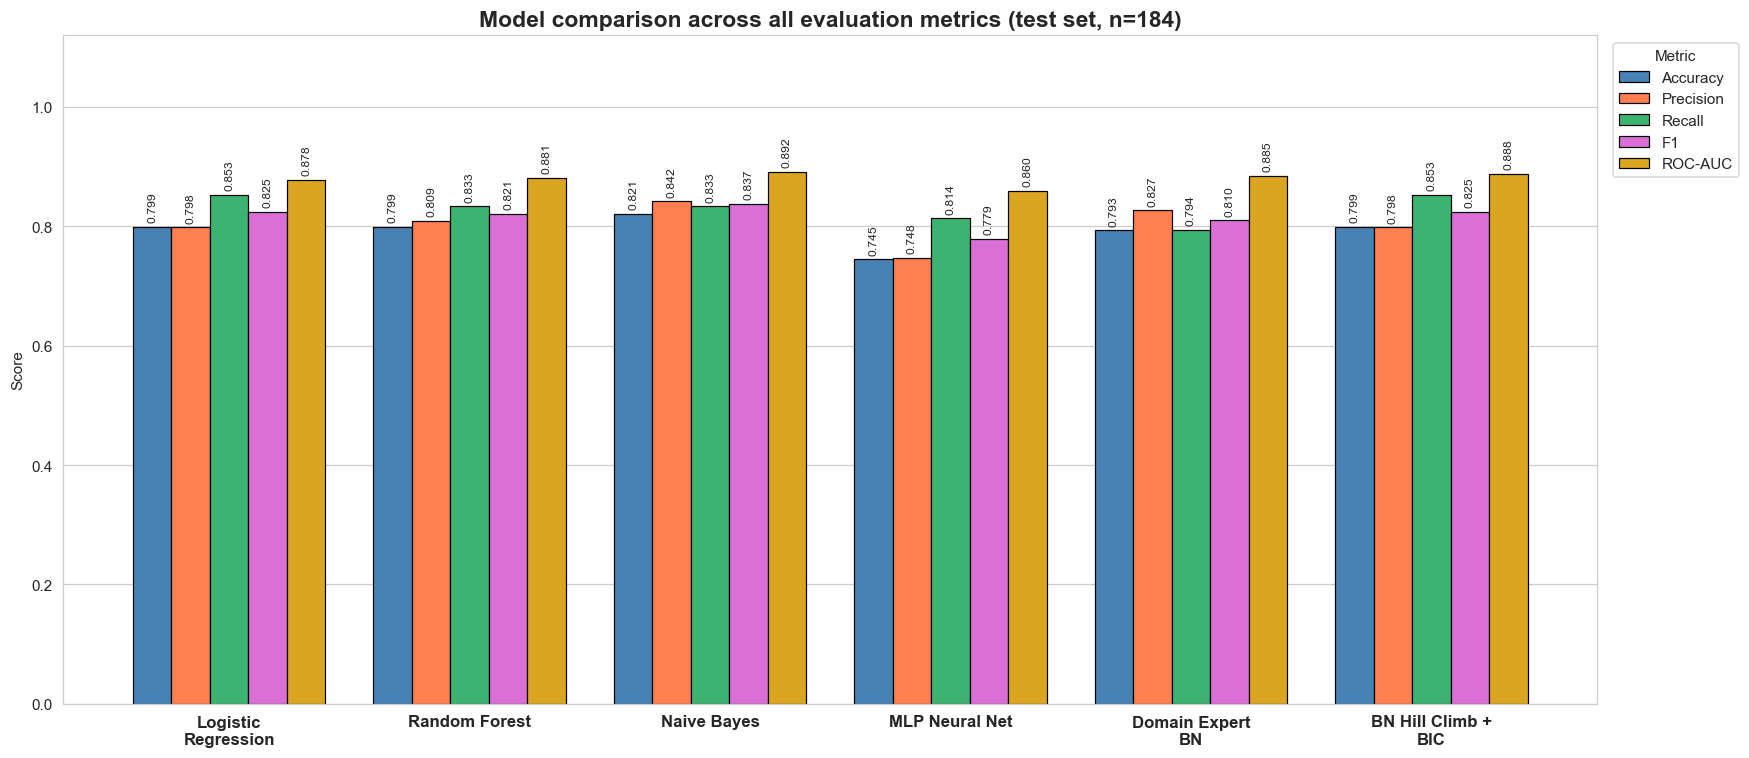

In [27]:
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
metric_colors = ['steelblue', 'coral', 'mediumseagreen', 'orchid', 'goldenrod']

x = np.arange(len(results_df))
width = 0.16

fig, ax = plt.subplots(figsize=(16, 7))
for i, (metric, color) in enumerate(zip(METRICS, metric_colors)):
    bars = ax.bar(x + i * width, results_df[metric], width, label=metric,
                  color=color, edgecolor='black', linewidth=0.8)
    ax.bar_label(bars, fmt='%.3f', fontsize=8, rotation=90, padding=3)

ax.set_xticks(x + width * 2)
ax.set_xticklabels([textwrap.fill(m, 15) for m in results_df['Model']],
                   fontsize=11, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.12)
ax.set_title('Model comparison across all evaluation metrics (test set, n=184)',
             fontsize=15, fontweight='bold')
ax.legend(title='Metric', loc='upper left', bbox_to_anchor=(1.005, 1))
ax.grid(axis='x', visible=False)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'model_comparison.png', bbox_inches='tight')
plt.show()

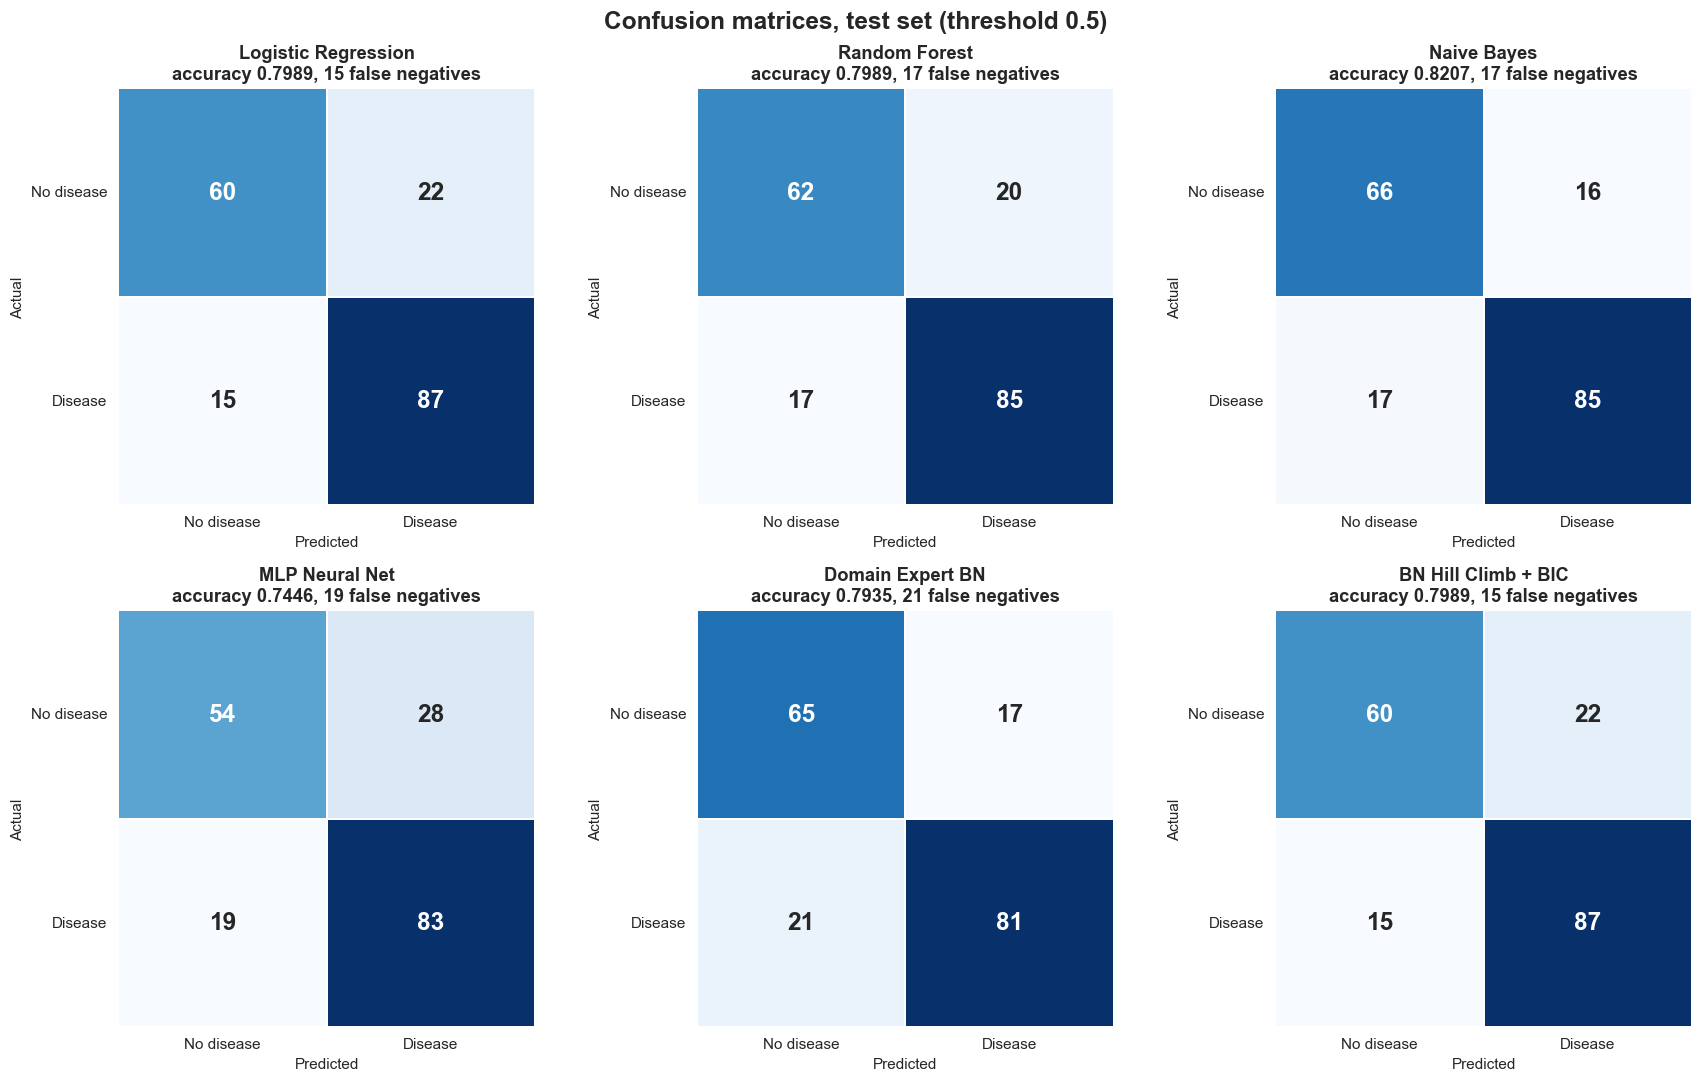

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues', cbar=False, square=True,
                linewidths=1.2, annot_kws={'fontsize': 16, 'fontweight': 'bold'},
                xticklabels=['No disease', 'Disease'],
                yticklabels=['No disease', 'Disease'])
    ax.set_title(f'{name}\naccuracy {accuracy_score(y_test, y_pred):.4f}, '
                 f'{cm[1, 0]} false negatives', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(rotation=0)

fig.suptitle('Confusion matrices, test set (threshold 0.5)', fontsize=16, fontweight='bold')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrices.png', bbox_inches='tight')
plt.show()

### Accuracy against interpretability

The interpretability values on the horizontal axis are a **subjective ranking we assigned**, not a
measured quantity. They are ordered by how directly a model's output can be traced back to its
inputs: a Bayesian Network exposes an explicit graph of named variables with conditional
probability tables that can be read off directly, logistic regression exposes signed coefficients,
Naive Bayes exposes per-feature likelihood ratios, a random forest requires post-hoc attribution,
and an MLP offers none of this. The chart is a qualitative summary, and no numerical claim should
be read off the horizontal axis.

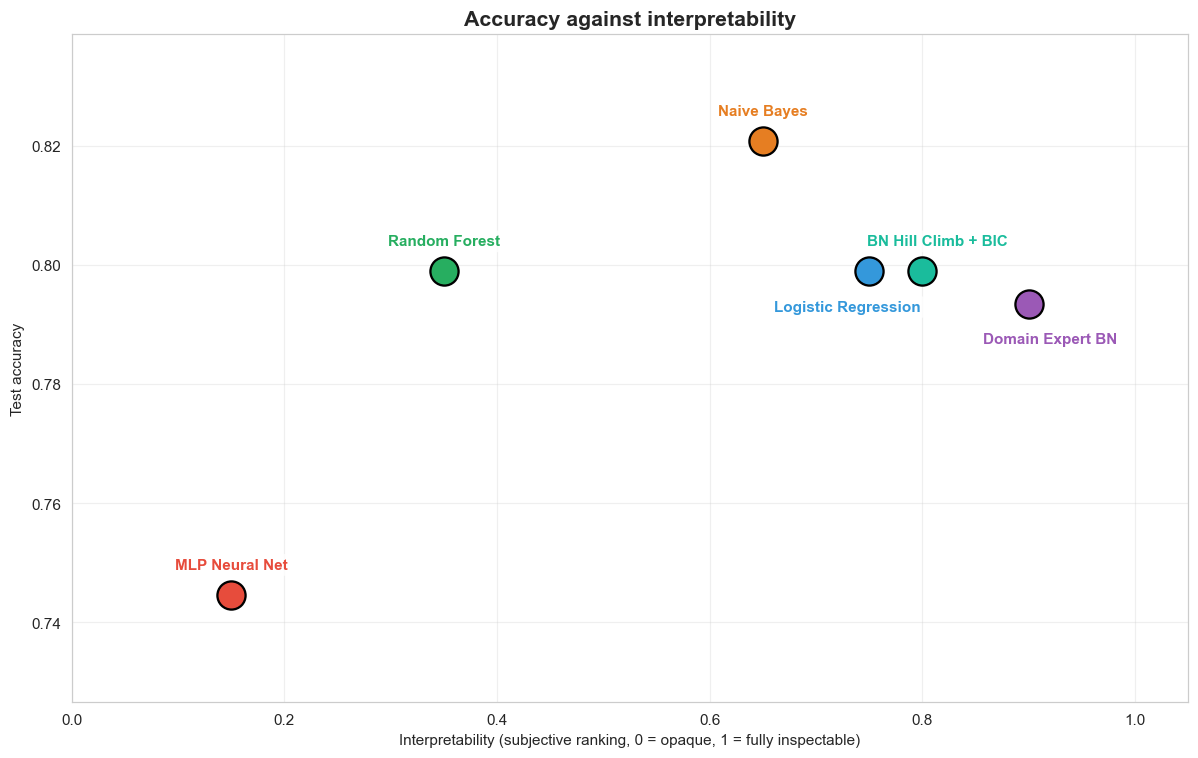

In [29]:
INTERPRETABILITY = {
    'Logistic Regression': 0.75,
    'Random Forest': 0.35,
    'Naive Bayes': 0.65,
    'MLP Neural Net': 0.15,
    'Domain Expert BN': 0.90,
    'BN Hill Climb + BIC': 0.80,
}
MODEL_COLORS = {
    'Logistic Regression': '#3498DB',
    'Random Forest': '#27AE60',
    'Naive Bayes': '#E67E22',
    'MLP Neural Net': '#E74C3C',
    'Domain Expert BN': '#9B59B6',
    'BN Hill Climb + BIC': '#1ABC9C',
}

LABEL_OFFSETS = {
    'Logistic Regression': (-14, -26),
    'Random Forest': (0, 17),
    'Naive Bayes': (0, 17),
    'MLP Neural Net': (0, 17),
    'Domain Expert BN': (14, -26),
    'BN Hill Climb + BIC': (10, 17),
}

fig, ax = plt.subplots(figsize=(11, 7))
for _, row in results_df.iterrows():
    name = row['Model']
    x, y = INTERPRETABILITY[name], row['Accuracy']
    ax.scatter(x, y, s=340, color=MODEL_COLORS[name],
               edgecolors='black', linewidths=1.5, zorder=5)
    ax.annotate(name, (x, y), textcoords='offset points', xytext=LABEL_OFFSETS[name],
                ha='center', fontsize=10, fontweight='bold', color=MODEL_COLORS[name],
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.8),
                zorder=6)

ax.set_xlabel('Interpretability (subjective ranking, 0 = opaque, 1 = fully inspectable)')
ax.set_ylabel('Test accuracy')
ax.set_title('Accuracy against interpretability', fontsize=14, fontweight='bold')
ax.set_xlim(0, 1.05)
ax.set_ylim(results_df['Accuracy'].min() - 0.018, results_df['Accuracy'].max() + 0.018)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'accuracy_vs_interpretability.png', bbox_inches='tight')
plt.show()

---
## 13. Results

### Headline numbers

In [30]:
best_acc = results_df.loc[results_df['Accuracy'].idxmax()]
best_auc = results_df.loc[results_df['ROC-AUC'].idxmax()]
spread = results_df['Accuracy'].max() - results_df['Accuracy'].min()

print(f'Patients            : {len(raw_df)} ({len(train)} train / {len(test)} test)')
print(f'Disease prevalence  : {clean_df["target"].mean():.1%}')
print(f'Best accuracy       : {best_acc["Model"]} at {best_acc["Accuracy"]:.4f}')
print(f'Best ROC-AUC        : {best_auc["Model"]} at {best_auc["ROC-AUC"]:.4f}')
print(f'Accuracy spread     : {spread:.4f} across all six models')
print()
print(f'Figures written to {RESULTS_DIR.relative_to(REPO_ROOT).as_posix()}/')
for f in sorted(RESULTS_DIR.glob('*.png')):
    print(f'  {f.name}')

Patients            : 920 (736 train / 184 test)
Disease prevalence  : 55.3%
Best accuracy       : Naive Bayes at 0.8207
Best ROC-AUC        : Naive Bayes at 0.8918
Accuracy spread     : 0.0761 across all six models

Figures written to results/
  accuracy_vs_interpretability.png
  approx_vs_exact.png
  bn_structures.png
  confusion_matrices.png
  correlation_and_balance.png
  eda_distributions.png
  inference_demo.png
  model_comparison.png
  pca_kmeans.png
  sequential_diagnosis.png
  vpi_ranking.png


### What the numbers say

Five of the six models sit inside 2.7 accuracy points of each other (0.7935 to 0.8207); only the
MLP falls away, at 0.7446. With 184 test patients one accuracy point is under two patients, so the
ordering among those five should not be read as a real ranking, because a single train/test
split cannot separate them. Naive Bayes leads on both accuracy and ROC-AUC, but not by a
margin this evaluation can support.

The results that do hold up:

- **The Bayesian Networks are competitive.** Neither BN beats the best baseline on accuracy, but
  both are in the same range while additionally supporting partial-evidence queries and
  next-test selection, which none of the baselines can do.
- **The MLP is the weakest model here.** It has the lowest accuracy and ROC-AUC of the six. On 736
  training rows of discretised categorical features there is nothing for the extra capacity to
  exploit, and `early_stopping` leaves only ~66 rows for validation, which makes the fit unstable.
- **The learned structure is sparse.** Hill Climbing with BIC keeps only a handful of edges around
  `target`, and its Markov blanket contains just six features, so the BIC complexity
  penalty is doing exactly what it is supposed to do.
- **The two BN structures perform almost identically** despite looking quite different, which
  suggests most of the predictive signal sits in a small set of exercise-test variables that both
  networks capture.

### Figures

| File | Content |
|---|---|
| `eda_distributions.png` | All 13 features split by disease status |
| `correlation_and_balance.png` | Correlation matrix and class balance |
| `pca_kmeans.png` | PCA projection and K-Means clusters |
| `bn_structures.png` | Domain-expert and learned network graphs |
| `inference_demo.png` | Posterior updating under partial evidence |
| `approx_vs_exact.png` | Likelihood Weighting converging on Variable Elimination |
| `vpi_ranking.png` | Information gain and VPI per candidate test |
| `sequential_diagnosis.png` | Posterior across a sequence of ordered tests |
| `model_comparison.png` | All models across all five metrics |
| `confusion_matrices.png` | Per-model confusion matrices |
| `accuracy_vs_interpretability.png` | Accuracy against subjective interpretability |

---
## 14. Conclusion

The project covers a full pipeline on the 920-patient UCI Heart Disease data: leakage-free
preprocessing, unsupervised exploration, four supervised baselines, two Bayesian Networks (one
hand-built, one learned by Hill Climbing on BIC), exact and approximate inference, and
information-theoretic and decision-theoretic test selection.

What we would emphasise:

1. **Preprocessing decisions mattered more than model choice.** The single largest correctness
   issue was treating `oldpeak = 0` as a missing value. Zero ST depression is a normal reading held
   by 370 of 858 patients, and those patients have half the disease rate of the rest. Recoding
   them as missing and mode-imputing them destroyed the most informative level of a strong
   predictor. Fixing that mattered more than any hyperparameter.

2. **A reward matrix implies a threshold.** Writing down asymmetric costs and then still
   thresholding at 0.5 is inconsistent. Here the utility-optimal cut-off is 0.167, and moving to
   it cuts false negatives substantially at the cost of precision.

3. **Informative is not the same as decision-relevant.** Several tests reduce uncertainty about
   the diagnosis measurably, but only one has non-zero VPI given the starting evidence. The
   rest would not change what is decided.

4. **Interpretability is the Bayesian Networks' real advantage, not accuracy.** They did not win
   on accuracy. What they provide is a readable graph, calibrated posteriors from any subset of
   evidence, and a principled way to ask which test to run next.

### Limitations

- **Heavy missingness in three columns.** `ca` is missing for 66% of patients, `thal` for 53% and
  `slope` for 34%, almost entirely because the non-Cleveland sites did not record them. Filling
  two thirds of a column with the training mode makes that column close to a constant, so any
  edge involving `ca` or `thal` should be read with caution.
- **Single train/test split.** All numbers come from one 80/20 split with no cross-validation and
  no repeated seeds, so the differences between models are within noise. Confidence intervals
  would need repeated resampling.
- **Nominal codes treated as numeric.** Logistic Regression, Random Forest and the MLP receive
  `cp`, `restecg`, `slope` and `thal` as integers, which imposes an ordering that does not exist
  for the nominal ones. One-hot encoding would be the correct treatment. The BNs and
  `CategoricalNB` are unaffected, since they treat every state as a distinct category.
- **Discretisation loses information.** Binning the five continuous features into three levels each
  is required for the discrete BNs but discards resolution the continuous models could have used.
- **No hyperparameter tuning.** Every model runs at close to library defaults, so the comparison is
  between untuned baselines rather than between best-achievable versions of each method.
- **Reward values are our own.** The +5 / +2 / -1 / -10 matrix is a plausible ordering of clinical
  error costs that we chose ourselves. It is not taken from any clinical source, and the 0.167
  threshold it produces is only as defensible as those numbers.
- **Not a clinical tool.** This works with a small, decades-old research dataset that has
  substantial missing data. Nothing here has been validated on any external population, and none
  of it is suitable for diagnostic use.